In [21]:
#Pretesting
import json

with open("../../data/CINE_MULTI/id_slice_info_valid.json", "r") as f:
  slice_info = json.load(f)

# Inspect the structure of the first entry
first_key = list(slice_info.keys())[0]
print(f"Patient ID: {first_key}")
print("Metadata content:", slice_info[first_key])

Patient ID: 106
Metadata content: 30


## Setup Imports

In [25]:
from monai.utils import first, set_determinism
from monai.transforms import (
    Compose,
    EnsureChannelFirstd,
    EnsureTyped,
    LoadImaged,
    NormalizeIntensityd,
    RandAffined,
    ResizeWithPadOrCropd,
    NormalizeIntensityd,
)
from monai.handlers.utils import from_engine
from monai.networks.nets import UNet
from monai.networks.layers import Norm
from monai.metrics import DiceMetric
from monai.losses import DiceLoss
from monai.inferers import sliding_window_inference
from monai.data import CacheDataset, DataLoader, Dataset, decollate_batch
from monai.config import print_config
from monai.apps import download_and_extract
import torch
import matplotlib.pyplot as plt
import tempfile
import shutil
import os
import glob
import torch
import nibabel as nib
from sklearn.model_selection import train_test_split
import numpy as np

print("All core dependencies loaded cleanly.")

All core dependencies loaded cleanly.


## Setup dataset paths

In [ ]:
#For this early stage we will only be using the short axis (SAX) images, as the 2CH and 4CH images will be used during the Multi-View stage.

from pathlib import Path

data_dir = Path("../../data/CINE_MULTI")

def get_data_dict(view: str, split: str) -> list[dict[str, str]]:
    folder = data_dir / f"{view}_{split.upper()}"
    images = sorted(folder.glob("image/*.nii.gz"))
    labels = sorted(folder.glob("anno/*.nii.gz"))
    
    assert len(images) == len(labels), f"Mismatch in {folder}: {len(images)} images vs {len(labels)} labels"
    return [{"image": str(img), "label": str(lbl)} for img, lbl in zip(images, labels)]

# Generate the dictionaries
data_dict_SAX_train = get_data_dict("SAX", "TR")
data_dict_SAX_test   = get_data_dict("SAX", "VAL")

data_dict_2CH_train = get_data_dict("2CH", "TR")
data_dict_2CH_test   = get_data_dict("2CH", "VAL")

data_dict_4CH_train = get_data_dict("4CH", "TR")
data_dict_4CH_test   = get_data_dict("4CH", "VAL")



#No need for cross validation, as MICCAI dataset includes its own testing set, at a 7:1 ratio of training to testing data.
#Snippet left in, just in case

#Setting up cross validation
# train_files, val_files = train_test_split(
#    data_dict_SAX,
#    test_size=0.20,  # 20% held out for validation
#    random_state=42,  # Fixed seed ensures identical split across runs
#    shuffle=True,
# )

print(f"Training cases:   {len(data_dict_SAX_train)}")
print(f"Testing cases: {len(data_dict_SAX_test)}")

Training cases:   105
Validation cases: 15


In [3]:
#For reproducibility and deterministic behaviour
set_determinism(seed=0)

## Setup transforms for training and validation

In [22]:
# 1. To view raw, untouched data:
raw_transforms = Compose(
    [
        LoadImaged(keys=["image", "label"]),
        EnsureChannelFirstd(keys=["image", "label"]),
    ]
)

# 2. To feed into your 2D U-Net baseline:
train_transforms = Compose(
    [
        LoadImaged(keys=["image", "label"]),
        EnsureChannelFirstd(keys=["image", "label"]),
        # Normalizes MRI intensities (zero mean, unit variance)
        NormalizeIntensityd(keys=["image"], nonzero=True, channel_wise=True),
        # Standardizes all in-plane slices to a consistent H x W (e.g. 256x256)
        ResizeWithPadOrCropd(keys=["image", "label"], spatial_size=(256, 256,-1)),
        # Lightweight 2D data augmentation
        RandAffined(
            keys=["image", "label"],
            prob=0.5,
            rotate_range=(0.2),  # ~11 degrees in-plane rotation
            scale_range=(0.1, 0.1),
            mode=("bilinear", "nearest"),
        ),
        EnsureTyped(keys=["image", "label"]),
    ]
)

# For a 3D volume, specify all 3 spatial axes (H, W, Z):
test_transforms = Compose(
    [
        LoadImaged(keys=["image", "label"]),
        EnsureChannelFirstd(keys=["image", "label"]),
        NormalizeIntensityd(keys=["image"], nonzero=True, channel_wise=True),
        # Pad/crop the 2D plane to 256x256 while leaving the third axis untouched (-1)
        ResizeWithPadOrCropd(
            keys=["image", "label"], spatial_size=(256, 256, -1)
        ),
        EnsureTyped(keys=["image", "label"]),
    ]
)

## Check transforms in DataLoader

image shape: torch.Size([149, 144, 275]), label shape: torch.Size([149, 144, 275])


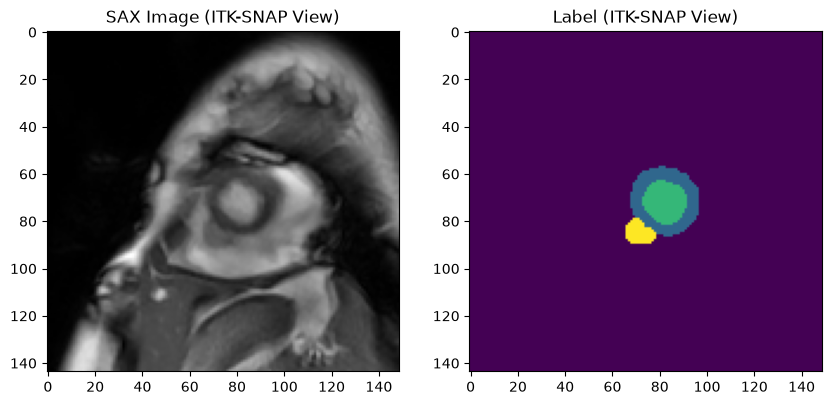

In [34]:
check_ds = Dataset(data=data_dict_SAX_train, transform=raw_transforms)
check_loader = DataLoader(check_ds, batch_size=1)
check_data = first(check_loader)
image, label = (check_data["image"][0][0], check_data["label"][0][0])
print(f"image shape: {image.shape}, label shape: {label.shape}")

#plot the slice [:, :, 270]

# Transpose to swap (X, Y) NIfTI memory coordinates to (row, col)
# so Matplotlib renders the slice the same way ITK-SNAP does.
aligned_slice = image[:, :, 40].cpu().numpy().T
aligned_label = label[:, :, 40].cpu().numpy().T

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("SAX Image (ITK-SNAP View)")
plt.imshow(aligned_slice, cmap="gray")

plt.subplot(1, 2, 2)
plt.title("Label (ITK-SNAP View)")
plt.imshow(aligned_label)
plt.show()

## Define CacheDataset and DataLoader for training and validation

Here we use CacheDataset to accelerate training and validation process, it's 10x faster than the regular Dataset.  
To achieve best performance, set `cache_rate=1.0` to cache all the data, if memory is not enough, set lower value.  
Users can also set `cache_num` instead of `cache_rate`, will use the minimum value of the 2 settings.  
And set `num_workers` to enable multi-threads during caching.  
If want to to try the regular Dataset, just change to use the commented code below.

In [ ]:
train_ds = CacheDataset(data=train_files, transform=train_transforms, cache_rate=1.0, num_workers=4)
# train_ds = Dataset(data=train_files, transform=train_transforms)

# use batch_size=2 to load images and use RandCropByPosNegLabeld
# to generate 2 x 4 images for network training
train_loader = DataLoader(train_ds, batch_size=2, shuffle=True, num_workers=4)

val_ds = CacheDataset(data=val_files, transform=val_transforms, cache_rate=1.0, num_workers=4)
# val_ds = Dataset(data=val_files, transform=val_transforms)
val_loader = DataLoader(val_ds, batch_size=1, num_workers=4)

## Create Model, Loss, Optimiser

In [12]:
# standard PyTorch program style: create UNet, DiceLoss and Adam optimizer
device = torch.device("cuda:0" if torch.cuda.device_count() > 0 else "cpu")
model = UNet(
    spatial_dims=3,
    in_channels=1,
    out_channels=2,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    num_res_units=2,
    norm=Norm.BATCH,
).to(device)
loss_function = DiceLoss(to_onehot_y=True, softmax=True)
optimizer = torch.optim.Adam(model.parameters(), 1e-4)
dice_metric = DiceMetric(include_background=False, reduction="mean")